# Chapter 84: Labor Supply, Participation, and Household Insurance

This notebook reruns four worked examples from the chapter: when a job seeker stops searching, where the child penalty comes from, a steady wage as insurance, and how self-selection moves sector averages. Every number is one of the chapter's hypothetical values; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def utility_curve(ax, u, x_max, x_min=0.0, col="navy", text=None, n=300):
    """Plot u(x) on [x_min, x_max]; ``u`` is a vectorised function. Returns (x, u(x))."""
    x = np.linspace(x_min, x_max, n)
    y = u(x)
    ax.plot(x, y, color=color(col), linewidth=2.2)
    if text:
        label(ax, x[-1], y[-1], text, col=col, dx=-4, dy=-14, ha="right", va="top")
    return x, y


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def join_and(items):
    """'a', 'a and b', 'a, b and c'."""
    items = [str(i) for i in items]
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]


def search_participation(p, J, k):
    """discouraged-worker-effect (chapter 84): search when pJ >= k.

    Book: p 0.10, J 2,000 gives pJ 200 >= 120 (search); p 0.04 gives 80 < 120 (stop);
    p 0.07 gives 140; cost 70 after reimbursement. Returns expected surplus, margin and decision.
    """
    ev = p * J
    return {"pJ": ev, "margin": ev - k, "search": ev >= k}


def unemployment_rate(E, U):
    """u = U / (E + U). discouraged-worker-effect (chapter 84): 100 / 1,000 = 10%; 80 / 980 = 8.16%."""
    return U / (E + U)


def time_constraint_hours(C, relatives, formal, split="mother", base=40.0, wage=30.0):
    """child-penalty (chapter 84): care constraint t_m + t_f + t_paid >= C.

    Uncovered hours C - relatives - formal (floored at 0) come out of paid hours, all from the
    mother (split="mother") or half each (split="equal"). Book: C 50, relatives 10, formal 20,
    40 hours at $30: mother 20 hours, $600, penalty 50%; equal split 30 hours each, $900, 25%;
    formal 40 removes the penalty.
    """
    uncovered = max(C - relatives - formal, 0.0)
    if split == "equal":
        cut_m = cut_f = uncovered / 2
    else:
        cut_m, cut_f = uncovered, 0.0
    hm, hf = base - cut_m, base - cut_f
    full = base * wage
    return {"uncovered": uncovered, "hours_m": hm, "hours_f": hf, "care_m": cut_m, "care_f": cut_f,
            "earn_m": hm * wage, "earn_f": hf * wage,
            "penalty_m": (full - hm * wage) / full, "penalty_f": (full - hf * wage) / full}


def roy_sorting(options, costs=None):
    """roy-self-selection-model (chapter 84): each person picks argmax_j {p_j q_ij - c_ij}.

    ``options`` maps name -> tuple of payoffs by sector; ``costs`` maps name -> tuple of costs
    (default zero). Ties go to the first sector. Returns choice index, observed pay (gross payoff
    in the chosen sector) and observed mean pay per sector (None if empty).
    Book (coding, sales): Ana (70,50), Ben (60,58), Cara (48,65), Dev (40,55): means 65 and 60;
    coding +10% and Dev's 12 licence cost: Dev codes, coding mean (77+66+44)/3 = 62.33.
    """
    names = list(options)
    k = len(next(iter(options.values())))
    choice, net = {}, {}
    for n in names:
        c = (costs or {}).get(n, (0.0,) * k)
        nets = [options[n][j] - c[j] for j in range(k)]
        j = max(range(k), key=lambda i: (nets[i], -i))
        choice[n], net[n] = j, nets
    means = []
    for j in range(k):
        pays = [options[n][j] for n in names if choice[n] == j]
        means.append(sum(pays) / len(pays) if pays else None)
    return {"choice": choice, "net": net, "means": means,
            "members": [[n for n in names if choice[n] == j] for j in range(k)]}


def expected_utility(probs, utils):
    """Probability-weighted utility. expected-utility-theorem: EU(A) = 0.5 sqrt(100) + 0.5 sqrt(25) = 7.5."""
    if abs(sum(probs) - 1.0) > 1e-9:
        raise ValueError("probabilities must sum to one")
    return float(sum(p * v for p, v in zip(probs, utils)))


plt.rcParams.update(HOUSE_RC)


labor = SimpleNamespace(search_participation=search_participation, unemployment_rate=unemployment_rate, time_constraint_hours=time_constraint_hours, roy_sorting=roy_sorting)


choice = SimpleNamespace(expected_utility=expected_utility)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'discouraged-worker-effect': {'J': 2000,
                               'k': 120,
                               'p': 0.1,
                               'pJ': 200,
                               'p_low': 0.04,
                               'pJ_low': 80,
                               'k_reimbursed': 70,
                               'p_recovery': 0.07,
                               'pJ_recovery': 140,
                               'E': 900,
                               'U': 100,
                               'discouraged': 20,
                               'u': 0.1,
                               'u_after_printed_as': 0.082,
                               'u_after_exact_4dp': 0.0816},
 'child-penalty': {'wage': 30,
                   'hours': 40,
                   'earn': 1200,
                   'C': 50,
                   'relatives': 10,
                   'formal': 20,
                   'formal_full': 40,
                   'hours_m': 20,
                   'earn_m': 600,
                   'penalty_m': 0.5,
                   'earn_equal': 900,
                   'penalty_equal': 0.25,
                   'wage_later': 27,
                   'earn_later': 1080,
                   'penalty_later': 0.1},
 'implicit-contract-smoothing': {'boom': 40,
                                 'slump': 16,
                                 'mean': 28,
                                 'eu_spot': 5.16,
                                 'wage': 27,
                                 'u_wage': 5.2,
                                 'margin_boom': 13,
                                 'margin_slump': -11,
                                 'margin_avg': 1,
                                 'slump_deep': 8,
                                 'margin_deep': -19},
 'roy-self-selection-model': {'workers': {'Ana': (70, 50),
                                          'Ben': (60, 58),
                                          'Cara': (48, 65),
                                          'Dev': (40, 55)},
                              'mean_coding': 65,
                              'mean_sales': 60,
                              'raise': 0.1,
                              'licence': 12,
                              'dev_sales_net': 43,
                              'mean_coding_after': 62.3,
                              'mean_without_dev': 71.5},
 'constructed': {'discouraged-worker-effect': {'p': [0.15], 'k': [170]},
                 'child-penalty': {'formal': [30]},
                 'implicit-contract-smoothing': {'slump': [24], 'wage': [26, 28]},
                 'roy-self-selection-model': {'raise': [0.2]}}}


def search_picture(p=0.10, k=120):
    b = BV["discouraged-worker-effect"]
    r = labor.search_participation(p, b["J"], k)
    ev = r["pJ"]
    u_all = labor.unemployment_rate(b["E"], b["U"])
    u_disc = labor.unemployment_rate(b["E"], b["U"] - b["discouraged"])
    fig, (ax1, ax2) = new_figure(ncols=2)
    bar_compare(ax1, ["Expected gain pJ", "Search cost k"], [ev, k], colors=["teal", "terracotta"],
                value_labels=[money(ev, 0), money(k, 0)], ylabel="Dollars", xlabel="Jordan's comparison")
    ax1.set_ylim(0, 340)
    bar_compare(ax2, ["All 100 search", "20 discouraged"], [100 * u_all, 100 * u_disc], colors=["navy", "gold"],
                value_labels=[pct(u_all), pct(u_disc)], ylabel="Measured unemployment rate (%)",
                xlabel="Town of 900 employed")
    ax2.set_ylim(0, 13)
    if ev > k:
        verdict, decision = "Jordan searches", "Search"
    elif ev < k:
        verdict, decision = "Jordan stops qualifying search", "Stop searching"
    else:
        verdict, decision = "Jordan is exactly indifferent (a tie)", "Indifferent (tie)"
    rel = ">" if ev > k else ("<" if ev < k else "=")
    metrics = {"Expected gain pJ": money(ev, 0), "Search cost k": money(k, 0), "Decision": decision,
               "Town rate, all search": pct(u_all), "Town rate, 20 discouraged": pct(u_disc)}
    steps = [f"pJ = {num(p)} x 2,000 = {num(ev, 0)}",
             f"Compare: {num(ev, 0)} {rel} {num(k, 0)}, so {verdict}",
             f"All searching: u = 100 / (900 + 100) = {pct(u_all)}",
             f"Twenty discouraged: u = 80 / (900 + 80) = {num(u_disc, 4)}, or {pct(u_disc)}"]
    interp = (f"Hypothetical numbers from the chapter. With a perceived job-finding probability of {num(p)}, Jordan's "
              f"expected gain is {num(p)} x 2,000 = {num(ev, 0)} dollars against a search cost of {money(k, 0)}, so "
              f"{verdict}. In the town, twenty discouraged searchers cut measured unemployment from {pct(u_all)} to "
              f"{pct(u_disc)} although nobody was hired.")
    alt = (f"Left: expected gain {money(ev, 0)} beside search cost {money(k, 0)}. Right: measured unemployment "
           f"{pct(u_all)} with all searching and {pct(u_disc)} after twenty stop.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def penalty_picture(care=20, split="mother"):
    b = BV["child-penalty"]
    r = labor.time_constraint_hours(b["C"], b["relatives"], care, split, b["hours"], b["wage"])
    fig, (ax1, ax2) = new_figure(ncols=2)
    stacked_bar(ax1, ["Mother", "Father"], [[r["hours_m"], r["hours_f"]], [r["care_m"], r["care_f"]]],
                ["Paid hours", "Uncovered care hours"], colors=["teal", "gold"], ylabel="Hours per week",
                total_marker=False)
    for x, (h, c) in enumerate([(r["hours_m"], r["care_m"]), (r["hours_f"], r["care_f"])]):
        label(ax1, x, h / 2, f"paid {num(h, 0)}", dx=0, dy=0, ha="center", va="center")
    ax1.set_ylim(0, 52)
    ax1.set_xlabel("Parent")
    ax1.legend(loc="upper center", ncol=2, frameon=False)
    pm, pf = r["penalty_m"], r["penalty_f"]
    bar_compare(ax2, ["Mother", "Father"], [100 * pm, 100 * pf], colors=["terracotta", "navy"],
                value_labels=[pct(pm, 1), pct(pf, 1)], ylabel="Earnings penalty (%)", xlabel="Parent")
    ax2.set_ylim(0, 60)
    unc = r["uncovered"]
    if abs(pm - pf) < 1e-9 and pm > 0:
        gap = "both lose the same share and the gendered penalty is zero"
    elif pm == 0 and pf == 0:
        gap = "neither parent loses paid hours"
    else:
        gap = f"the gendered gap is {pct(pm - pf, 1)}"
    who = "the mother" if split == "mother" else "both parents equally"
    cover = f"covered by {who}" if unc > 0 else "and no parent needs to cover care"
    metrics = {"Uncovered care hours": num(unc, 0), "Mother paid hours": num(r["hours_m"], 0),
               "Mother weekly earnings": money(r["earn_m"], 0), "Mother penalty": pct(pm, 1),
               "Father weekly earnings": money(r["earn_f"], 0), "Father penalty": pct(pf, 1)}
    steps = [f"Uncovered = 50 - 10 - {num(care, 0)} = {num(unc, 0)} hours, {cover}",
             f"Mother: 40 - {num(r['care_m'], 0)} = {num(r['hours_m'], 0)} hours x $30 = {money(r['earn_m'], 0)}",
             f"Father: 40 - {num(r['care_f'], 0)} = {num(r['hours_f'], 0)} hours x $30 = {money(r['earn_f'], 0)}",
             f"Mother penalty = (1,200 - {num(r['earn_m'], 0)}) / 1,200 = {pct(pm, 1)}; "
             f"father = (1,200 - {num(r['earn_f'], 0)}) / 1,200 = {pct(pf, 1)}"]
    interp = (f"Hypothetical family from the chapter. With {num(care, 0)} formal hours, 50 - 10 - {num(care, 0)} = "
              f"{num(unc, 0)} care hours remain uncovered, {cover}. The mother earns {money(r['earn_m'], 0)} "
              f"(penalty {pct(pm, 1)}) and the father {money(r['earn_f'], 0)} (penalty {pct(pf, 1)}), so {gap}.")
    alt = (f"Left: stacked weekly hours, mother {num(r['hours_m'], 0)} paid and {num(r['care_m'], 0)} care, father "
           f"{num(r['hours_f'], 0)} paid and {num(r['care_f'], 0)} care. Right: penalties {pct(pm, 1)} and {pct(pf, 1)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def contract_picture(slump=16, wage=27):
    b = BV["implicit-contract-smoothing"]
    boom = b["boom"]
    eu_spot = choice.expected_utility([0.5, 0.5], [math.sqrt(boom), math.sqrt(slump)])
    u_fix = math.sqrt(wage)
    mb, ms = boom - wage, slump - wage
    avg = (mb + ms) / 2
    fig, (ax1, ax2) = new_figure(ncols=2)
    utility_curve(ax1, np.sqrt, 46, x_min=0, col="navy")
    ax1.plot([slump, boom], [math.sqrt(slump), math.sqrt(boom)], color=PALETTE["gold"], linewidth=1.8)
    mark(ax1, (slump + boom) / 2, eu_spot, f"spot EU {num(eu_spot)}", col="gold", dx=8, dy=-14, va="top")
    mark(ax1, wage, u_fix, f"fixed wage {num(u_fix)}", col="teal", dx=-8, dy=8, ha="right")
    ax1.set_xlim(0, 46)
    ax1.set_ylim(0, 7.6)
    ax1.set_xlabel("Wage ($)")
    ax1.set_ylabel("Utility sqrt(w)")
    bar_compare(ax2, ["Boom", "Slump", "Average"], [mb, ms, avg], colors=["teal", "terracotta", "navy"],
                value_labels=[num(mb, 1), num(ms, 1), num(avg, 1)], ylabel="Firm margin per worker ($)",
                xlabel="State")
    ax2.set_ylim(-25, 25)
    if u_fix > eu_spot:
        worker = "the worker prefers the fixed wage"
    elif u_fix < eu_spot:
        worker = "the worker prefers spot pay"
    else:
        worker = "the worker is indifferent"
    if avg > 0:
        firm = f"the firm earns {money(avg, 2)} on average for bearing risk"
    elif avg < 0:
        firm = f"the firm loses {money(-avg, 2)} on average"
    else:
        firm = "the firm just breaks even on average"
    metrics = {"Spot expected utility": num(eu_spot), "Fixed-wage utility": num(u_fix),
               "Firm margin, boom": num(mb, 1), "Firm margin, slump": num(ms, 1), "Firm average margin": num(avg, 1)}
    steps = [f"Spot EU = (sqrt(40) + sqrt({num(slump, 0)})) / 2 = ({num(math.sqrt(boom), 4)} + "
             f"{num(math.sqrt(slump), 4)}) / 2 = {num(eu_spot, 4)}",
             f"Fixed wage: sqrt({num(wage, 0)}) = {num(u_fix, 4)}, so {worker}",
             f"Margins: 40 - {num(wage, 0)} = {num(mb, 1)}; {num(slump, 0)} - {num(wage, 0)} = {num(ms, 1)}",
             f"Average margin = ({num(mb, 1)} + {signed1(ms)}) / 2 = {num(avg, 1)}"]
    interp = (f"Hypothetical two-state economy from the chapter. Spot pay of 40 or {num(slump, 0)} gives expected "
              f"utility {num(eu_spot)}; a fixed {money(wage, 0)} gives {num(u_fix)}, so {worker}. The firm's "
              f"margins are 40 - {num(wage, 0)} = {num(mb, 1)} in the boom and {num(slump, 0)} - {num(wage, 0)} = "
              f"{num(ms, 1)} in the slump, so {firm}.")
    alt = (f"Left: square-root utility with the spot chord at expected utility {num(eu_spot)} and the fixed wage "
           f"point at {num(u_fix)}. Right: firm margins {num(mb, 1)}, {num(ms, 1)} and average {num(avg, 1)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def signed1(v):
    t = num(v, 1)
    return f"({t})" if t.startswith("-") else t


def roy_picture(rise=0.0, lic=0):
    b = BV["roy-self-selection-model"]
    opts = {n: (c * (1 + rise), s) for n, (c, s) in b["workers"].items()}
    costs = {"Dev": (0.0, float(lic))}
    r = labor.roy_sorting(opts, costs)
    mc, ms = r["means"]
    fig, (ax1, ax2) = new_figure(ncols=2)
    ax1.plot([35, 95], [35, 95], color=PALETTE["grey"], linestyle="dashed", linewidth=1.4)
    label(ax1, 88, 88, "equal pay", col="grey", dx=-4, dy=4, ha="right")
    for n, (c, s) in opts.items():
        s_net = s - (lic if n == "Dev" else 0)
        codes = r["choice"][n] == 0
        mark(ax1, s_net, c, f"{n} ({num(c, 1)}, {num(s_net, 0)})", col="teal" if codes else "terracotta",
             dx=6, dy=-4 if n in ("Ben", "Cara") else 6, va="top" if n in ("Ben", "Cara") else "bottom")
    ax1.set_xlim(35, 95)
    ax1.set_ylim(35, 95)
    ax1.set_xlabel("Net sales pay ($000)")
    ax1.set_ylabel("Coding pay ($000)")
    vals = [mc if mc is not None else 0, ms if ms is not None else 0]
    labs = [num(mc, 1) if mc is not None else "none", num(ms, 1) if ms is not None else "none"]
    bar_compare(ax2, ["Coding", "Sales"], vals, colors=["teal", "terracotta"], value_labels=labs,
                ylabel="Observed mean pay ($000)", xlabel="Sector")
    ax2.set_ylim(0, 95)
    coders, sellers = r["members"]
    sum_c = " + ".join(num(opts[n][0], 1) for n in coders)
    sum_s = " + ".join(num(opts[n][1], 0) for n in sellers)
    metrics = {"Coders": join_and(coders), "Sellers": join_and(sellers),
               "Observed coding mean": num(mc, 2), "Observed sales mean": num(ms, 2)}
    dev_c, dev_s = opts["Dev"][0], opts["Dev"][1] - lic
    steps = [f"Coding pay x {num(1 + rise)}: Ana {num(opts['Ana'][0], 1)}, Ben {num(opts['Ben'][0], 1)}, "
             f"Cara {num(opts['Cara'][0], 1)}, Dev {num(dev_c, 1)}",
             f"Dev compares coding {num(dev_c, 1)} with net sales 55 - {lic} = {num(dev_s, 0)}",
             f"Coding mean = ({sum_c}) / {len(coders)} = {num(mc, 2)}",
             f"Sales mean = ({sum_s}) / {len(sellers)} = {num(ms, 2)}"]
    interp = (f"Hypothetical workers from the chapter. With coding pay up {pct(rise, 0)} and a sales licence cost of "
              f"{lic} for Dev, {join_and(coders)} code and {join_and(sellers)} {'sells' if len(sellers) == 1 else 'sell'}. The observed coding mean is "
              f"({sum_c}) / {len(coders)} = {num(mc, 2)} and the sales mean ({sum_s}) / {len(sellers)} = {num(ms, 2)} "
              f"(in $000). A change in who enters moves the averages "
              f"even when no incumbent's pay falls.")
    alt = (f"Left: the four workers placed by net sales pay and coding pay, coders in teal. Right: observed means, "
           f"coding {num(mc, 2)} and sales {num(ms, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Discouraged-worker effect: when does a job seeker stop searching?

Hypothetical numbers. An offer is worth \$2,000 and search costs \$120; the town has 900 employed and 100 searching.

$$pJ\geq k, \qquad pJ=0.10(2{,}000)=200, \qquad u=\frac{U}{E+U}$$

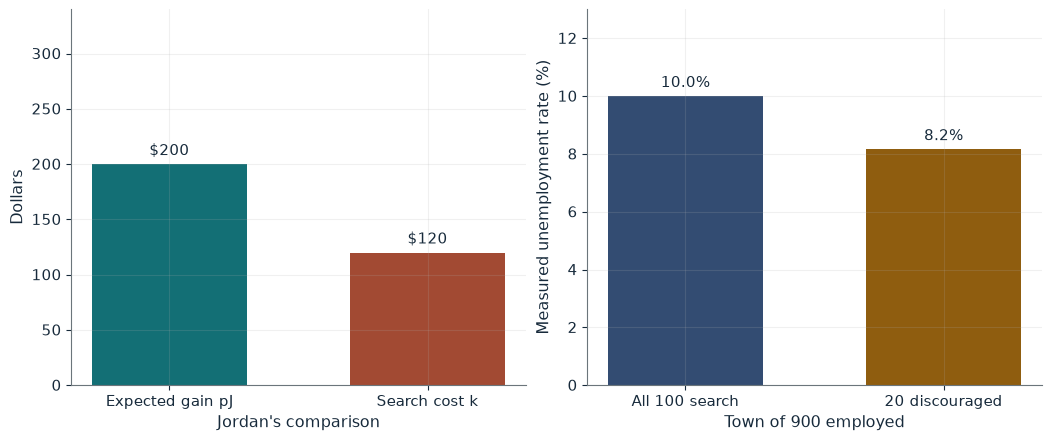

Expected gain pJ           $200
Search cost k              $120
Decision                   Search
Town rate, all search      10.0%
Town rate, 20 discouraged  8.2%

Worked steps:
  1. pJ = 0.10 x 2,000 = 200
  2. Compare: 200 > 120, so Jordan searches
  3. All searching: u = 100 / (900 + 100) = 10.0%
  4. Twenty discouraged: u = 80 / (900 + 80) = 0.0816, or 8.2%

Hypothetical numbers from the chapter. With a perceived job-finding probability of 0.10, Jordan's expected gain is 0.10 x 2,000 = 200 dollars against a search cost of $120, so Jordan searches. In the town, twenty discouraged searchers cut measured unemployment from 10.0% to 8.2% although nobody was hired.


In [2]:
show(search_picture(p=0.10, k=120))

Change one input, `p`, and hold the others at the book's values:

In [3]:
sweep(search_picture, 'p', [0.04, 0.07, 0.1, 0.15], {'k': 120}, ['Expected gain pJ', 'Decision'])

p | Expected gain pJ | Decision
0.04 | $80 | Stop searching
0.07 | $140 | Search
0.1 | $200 | Search
0.15 | $300 | Search


At p = 0.10 the expected gain of 200 beats the 120 cost; at 0.04 it is 80 and search stops. Twenty discouraged searchers cut the measured rate from 10 percent to 8.2 percent with no hiring.

## 2. Child penalty: where the penalty comes from

Hypothetical family: \$30 an hour, 40 hours each, 50 care hours, 10 from relatives.

$$t_m+t_f+t_{paid}\geq C, \qquad \frac{1{,}200-600}{1{,}200}=50\%$$

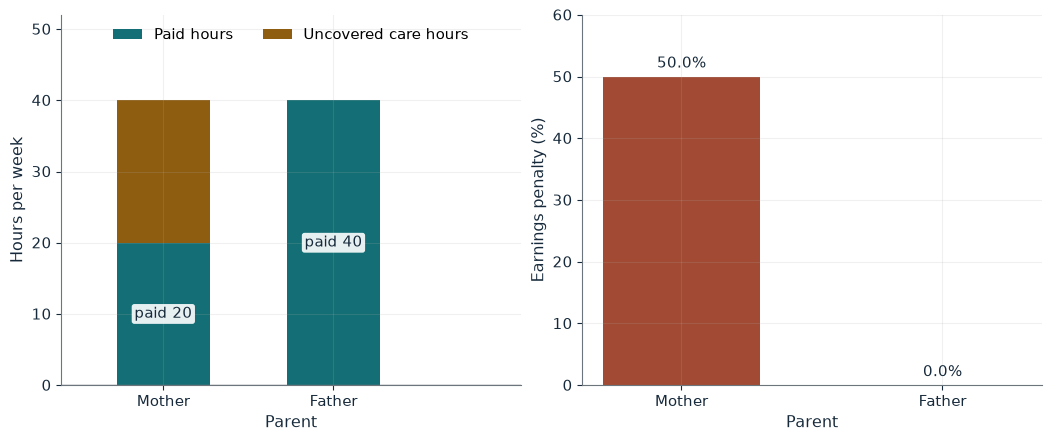

Uncovered care hours    20
Mother paid hours       20
Mother weekly earnings  $600
Mother penalty          50.0%
Father weekly earnings  $1,200
Father penalty          0.0%

Worked steps:
  1. Uncovered = 50 - 10 - 20 = 20 hours, covered by the mother
  2. Mother: 40 - 20 = 20 hours x $30 = $600
  3. Father: 40 - 0 = 40 hours x $30 = $1,200
  4. Mother penalty = (1,200 - 600) / 1,200 = 50.0%; father = (1,200 - 1,200) / 1,200 = 0.0%

Hypothetical family from the chapter. With 20 formal hours, 50 - 10 - 20 = 20 care hours remain uncovered, covered by the mother. The mother earns $600 (penalty 50.0%) and the father $1,200 (penalty 0.0%), so the gendered gap is 50.0%.


In [4]:
show(penalty_picture(care=20, split='mother'))

Change one input, `care`, and hold the others at the book's values:

In [5]:
sweep(penalty_picture, 'care', [20, 30, 40], {'split': 'mother'}, ['Mother paid hours', 'Mother penalty'])

care | Mother paid hours | Mother penalty
20 | 20 | 50.0%
30 | 30 | 25.0%
40 | 40 | 0.0%


With 20 formal hours the mother covers 20 hours and loses half her earnings. Full childcare removes the hours channel; an equal split gives both a 25 percent loss and no gender gap.

## 3. Implicit-contract smoothing: a steady wage as insurance

Hypothetical states: revenue 40 or 16, equally likely, utility sqrt(w).

$$\frac{\sqrt{40}+\sqrt{16}}{2}\approx5.16, \qquad \sqrt{27}\approx5.20$$

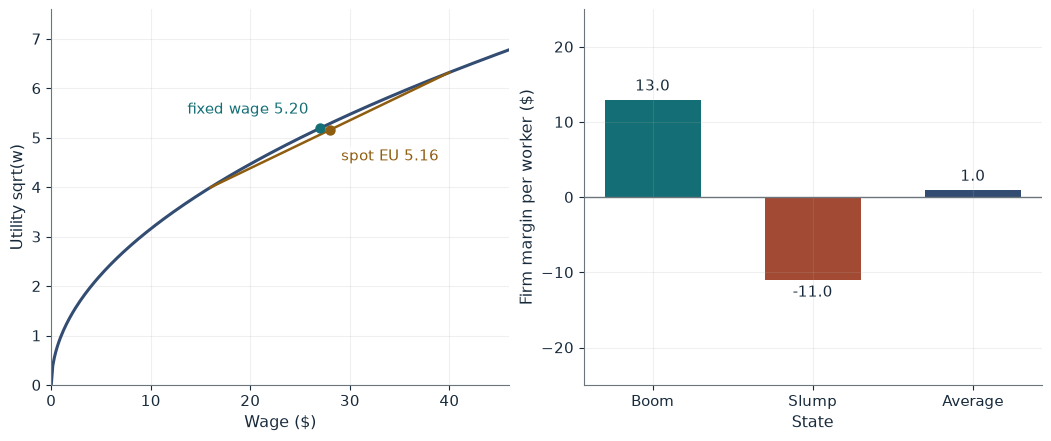

Spot expected utility  5.16
Fixed-wage utility     5.20
Firm margin, boom      13.0
Firm margin, slump     -11.0
Firm average margin    1.0

Worked steps:
  1. Spot EU = (sqrt(40) + sqrt(16)) / 2 = (6.3246 + 4.0000) / 2 = 5.1623
  2. Fixed wage: sqrt(27) = 5.1962, so the worker prefers the fixed wage
  3. Margins: 40 - 27 = 13.0; 16 - 27 = -11.0
  4. Average margin = (13.0 + (-11.0)) / 2 = 1.0

Hypothetical two-state economy from the chapter. Spot pay of 40 or 16 gives expected utility 5.16; a fixed $27 gives 5.20, so the worker prefers the fixed wage. The firm's margins are 40 - 27 = 13.0 in the boom and 16 - 27 = -11.0 in the slump, so the firm earns $1.00 on average for bearing risk.


In [6]:
show(contract_picture(slump=16, wage=27))

Change one input, `slump`, and hold the others at the book's values:

In [7]:
sweep(contract_picture, 'slump', [8, 16, 24], {'wage': 27}, ['Spot expected utility', 'Firm average margin'])

slump | Spot expected utility | Firm average margin
8 | 4.58 | -3.0
16 | 5.16 | 1.0
24 | 5.61 | 5.0


The worker prefers a sure 27 to the risky pair. The firm earns 13 in the boom and loses 11 in the slump, 1 on average; a deeper slump of 8 turns the average to -3.

## 4. Roy self-selection: who chooses coding, and what the average hides

Hypothetical workers, (coding, sales) in \$000: Ana (70, 50), Ben (60, 58), Cara (48, 65), Dev (40, 55).

$$j_i^*=\arg\max_j\{p_jq_{ij}-c_{ij}\}, \qquad \frac{77+66+44}{3}\approx62.3$$

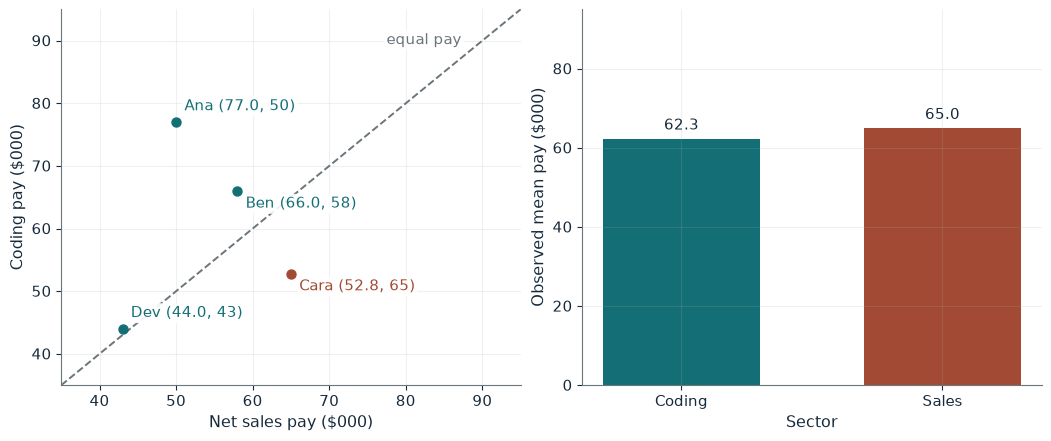

Coders                Ana, Ben and Dev
Sellers               Cara
Observed coding mean  62.33
Observed sales mean   65.00

Worked steps:
  1. Coding pay x 1.10: Ana 77.0, Ben 66.0, Cara 52.8, Dev 44.0
  2. Dev compares coding 44.0 with net sales 55 - 12 = 43
  3. Coding mean = (77.0 + 66.0 + 44.0) / 3 = 62.33
  4. Sales mean = (65) / 1 = 65.00

Hypothetical workers from the chapter. With coding pay up 10% and a sales licence cost of 12 for Dev, Ana, Ben and Dev code and Cara sells. The observed coding mean is (77.0 + 66.0 + 44.0) / 3 = 62.33 and the sales mean (65) / 1 = 65.00 (in $000). A change in who enters moves the averages even when no incumbent's pay falls.


In [8]:
show(roy_picture(rise=0.10, lic=12))

Change one input, `rise`, and hold the others at the book's values:

In [9]:
sweep(roy_picture, 'rise', [0.0, 0.1, 0.2], {'lic': 12}, ['Coders', 'Observed coding mean'])

rise | Coders | Observed coding mean
0.0 | Ana and Ben | 65.00
0.1 | Ana, Ben and Dev | 62.33
0.2 | Ana, Ben and Dev | 68.00


A 10 percent coding raise plus Dev's licence cost pulls Dev into coding, so the coding mean falls from 65 to 62.33 although both original coders earn more.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

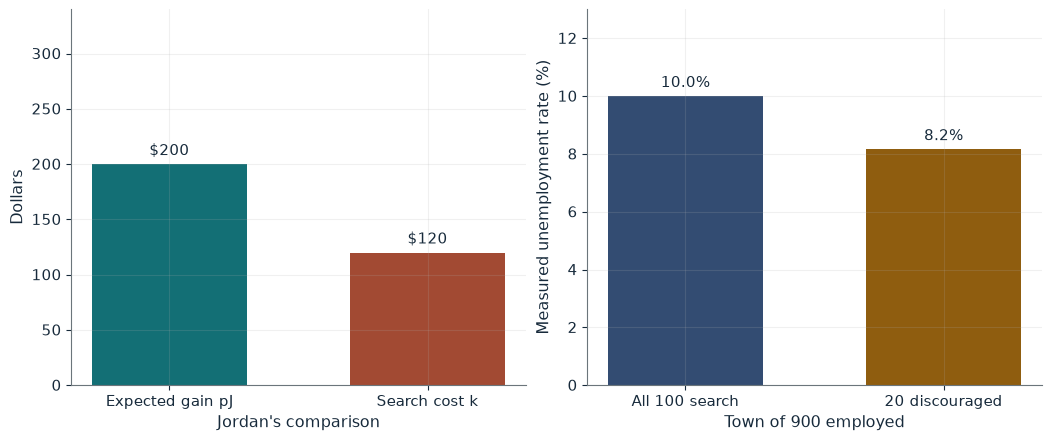

Expected gain pJ           $200
Search cost k              $120
Decision                   Search
Town rate, all search      10.0%
Town rate, 20 discouraged  8.2%

Worked steps:
  1. pJ = 0.10 x 2,000 = 200
  2. Compare: 200 > 120, so Jordan searches
  3. All searching: u = 100 / (900 + 100) = 10.0%
  4. Twenty discouraged: u = 80 / (900 + 80) = 0.0816, or 8.2%

Hypothetical numbers from the chapter. With a perceived job-finding probability of 0.10, Jordan's expected gain is 0.10 x 2,000 = 200 dollars against a search cost of $120, so Jordan searches. In the town, twenty discouraged searchers cut measured unemployment from 10.0% to 8.2% although nobody was hired.


In [10]:
show(search_picture(p=0.10, k=120))

## Practice

**1.** With p = 0.07 and a search cost of 170, does Jordan search?

<details><summary>Answer</summary>

pJ = 0.07 x 2,000 = 140, below 170, so no.

</details>

**2.** With 30 formal hours and the mother covering the rest, what is her penalty?

<details><summary>Answer</summary>

Uncovered 50 - 10 - 30 = 10; she works 30 hours for 900, so (1,200 - 900) / 1,200 = 25 percent.

</details>

**3.** With a 20 percent coding raise and no licence, what is the coding mean?

<details><summary>Answer</summary>

Ana 84 and Ben 72 code (Cara 57.6 < 65, Dev 48 < 55), so (84 + 72) / 2 = 78.

</details>